# EDA: Open-Meteo, archived day-ahead weather forecasts

**What the data is:** archived weather forecasts from the Open-Meteo *Previous Runs API*. For every hour the API returns what a weather model predicted about one day earlier. This is the only input of the G3 forecast that is really known in advance.

| | |
|---|---|
| Website | https://open-meteo.com/en/docs/previous-runs-api |
| Request used | `https://previous-runs-api.open-meteo.com/v1/forecast?latitude=47.04&longitude=8.30&hourly=shortwave_radiation_previous_day1,...&models=icon_d2,meteoswiss_icon_ch2&start_date=2024-01-01&end_date=2025-12-31&timezone=GMT` (script: `download_data.py`) |
| Models | `icon_d2` (German weather service, about 2 km), `meteoswiss_icon_ch2` (MeteoSwiss, about 2 km) |
| Licence | CC BY 4.0, attribution "Open-Meteo.com"; free for non-commercial use |
| Files | `data/previous_day1_<station>_2024-01-01_2025-12-31.json`, one per station location (LUZ, EGO, MOA, SPF), downloaded 30.10.2026; large files are not versioned, `data/sample_luz_first_hours.txt` shows the format. The comparison with measurements reads `../meteoswiss/data`: run the `download_data.py` there first |
| One row | one hour at one location; radiation in W/m², temperature in °C, cloud cover in % |
| Time span and resolution | hourly, 2024–2025: the part of our period 2019–2025 that exists (Q3) |
| Time zone | requested in UTC (GMT); **we work in Central European Time without clock changes (fixed CET = UTC+1) throughout the project** |

**How this notebook works:** same structure as `energy_charts_eda.ipynb`, but shorter: every section starts with a **question**, then the code, a chart where useful, and a note **Finding → Consequence**. *Step 1* validity (Q1–Q8), *Step 2* patterns and suitability (Q9–Q12).
*Prepared with AI assistance (Claude); findings to be questioned and checked by us.*

In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("data")
OUT = Path("../../data/processed")   # cleaned tables for the combined notebook
FIG = Path("../../figures/eda")   # plots for the README, as required by the course guide
FIG.mkdir(parents=True, exist_ok=True)
TZ = "Etc/GMT-1"   # fixed CET = UTC+1, no clock changes (the minus sign is correct for this name)
pd.set_option("display.max_columns", None)   # show all columns side by side
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"


def save(fig, name):
    fig.savefig(FIG / f"open_meteo_{name}.png", dpi=160, bbox_inches="tight")

# Step 1: Is the data valid?

## Q1: What does one raw file look like?

In [2]:
f = sorted(DATA.glob("previous_day1_LUZ_*.json"))[0]
raw = json.loads(f.read_text(encoding="utf-8"))
print("Keys:", list(raw.keys()))
print("Grid point:", raw["latitude"], raw["longitude"], "| elevation:", raw["elevation"], "m | time zone:", raw["timezone"])
print("Units:", {k: v for k, v in raw["hourly_units"].items()}.get("shortwave_radiation_previous_day1_icon_d2"))
print("First time stamps:", raw["hourly"]["time"][:2])
print("Columns:", [c for c in raw["hourly"] if c != "time"][:5], "...", len(raw["hourly"]) - 1, "in total")

Keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
Grid point: 47.03524 8.307981 | elevation: 455.0 m | time zone: GMT
Units: W/m²
First time stamps: ['2024-01-01T00:00', '2024-01-01T01:00']
Columns: ['shortwave_radiation_previous_day1_icon_d2', 'direct_radiation_previous_day1_icon_d2', 'diffuse_radiation_previous_day1_icon_d2', 'temperature_2m_previous_day1_icon_d2', 'cloud_cover_previous_day1_icon_d2'] ... 10 in total


> **Finding:** one JSON per location, with a list of time stamps and one list per variable and model (10 in total). The API moves the coordinates to the next grid point of the model, about 500 m from the station, at 455 m elevation like the station.
> **Consequence:** one pandas table, with a suffix for the model. The forecast is for a grid cell, the measurement for a point.

## Q2: Load all locations into one pandas table. Which columns and data types do we have?

In [3]:
LOCATIONS = ["LUZ", "EGO", "MOA", "SPF"]


def load_location(location):
    f = sorted(DATA.glob(f"previous_day1_{location}_*.json"))[0]
    h = json.loads(f.read_text(encoding="utf-8"))["hourly"]
    index = pd.DatetimeIndex(pd.to_datetime(h["time"], utc=True)).tz_convert(TZ)
    return pd.DataFrame({k.replace("_previous_day1", ""): v for k, v in h.items() if k != "time"}, index=index)


frames = {location: load_location(location) for location in LOCATIONS}
df = pd.concat(frames, names=["location", "time_local"]).reset_index(level="location")
print("Rows:", len(df), "| duplicated location + time stamp:", df.set_index("location", append=True).index.duplicated().sum())
df[df["location"] == "LUZ"].info()

Rows: 70176 | duplicated location + time stamp: 0
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 17544 entries, 2024-01-01 01:00:00+01:00 to 2026-01-01 00:00:00+01:00
Data columns (total 11 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   location                                 17544 non-null  object 
 1   shortwave_radiation_icon_d2              17097 non-null  float64
 2   direct_radiation_icon_d2                 17097 non-null  float64
 3   diffuse_radiation_icon_d2                17097 non-null  float64
 4   temperature_2m_icon_d2                   17097 non-null  float64
 5   cloud_cover_icon_d2                      17097 non-null  float64
 6   shortwave_radiation_meteoswiss_icon_ch2  4344 non-null   float64
 7   direct_radiation_meteoswiss_icon_ch2     4344 non-null   float64
 8   diffuse_radiation_meteoswiss_icon_ch2    4344 non-null   float64
 9   temperature_2m_mete

In [4]:
df[df["location"] == "LUZ"].drop(columns="location").describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
shortwave_radiation_icon_d2,17097.0,136.4,212.6,0.0,0.0,6.8,203.3,912.8
direct_radiation_icon_d2,17097.0,75.0,153.7,0.0,0.0,0.3,62.3,774.0
diffuse_radiation_icon_d2,17097.0,61.4,82.2,0.0,0.0,6.5,113.8,421.5
temperature_2m_icon_d2,17097.0,11.6,7.6,-7.6,5.7,11.3,17.1,34.5
cloud_cover_icon_d2,17097.0,73.2,37.1,0.0,52.0,96.0,100.0,100.0
shortwave_radiation_meteoswiss_icon_ch2,4344.0,133.9,209.7,0.0,0.0,2.0,209.2,909.0
direct_radiation_meteoswiss_icon_ch2,4344.0,77.7,153.8,0.0,0.0,0.0,76.0,791.0
diffuse_radiation_meteoswiss_icon_ch2,4344.0,56.3,78.9,0.0,0.0,2.0,102.2,472.0
temperature_2m_meteoswiss_icon_ch2,4344.0,12.8,7.8,-4.0,7.1,13.1,18.4,35.2
cloud_cover_meteoswiss_icon_ch2,4344.0,67.1,38.6,0.0,34.0,87.0,100.0,100.0


> **Finding:** all columns are numeric, no duplicates. ICON-D2 has 17,097 of 17,544 hours, ICON-CH2 only 4,344. The two models have a similar range. Cloud cover is mostly high (median 96 %).
> **Consequence:** radiation is the variable we use; cloud cover is a very coarse second input.

## Q3: Is every hour present? Where are values missing, and why?

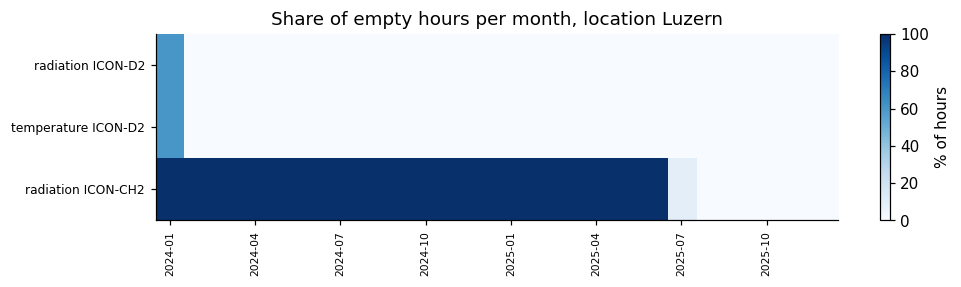

First value: {'shortwave_radiation_icon_d2': Timestamp('2024-01-19 16:00:00+0100', tz='Etc/GMT-1'), 'temperature_2m_icon_d2': Timestamp('2024-01-19 16:00:00+0100', tz='Etc/GMT-1'), 'shortwave_radiation_meteoswiss_icon_ch2': Timestamp('2025-07-04 01:00:00+0100', tz='Etc/GMT-1')}
Empty hours in the test year 2025: {'shortwave_radiation_icon_d2': 0, 'temperature_2m_icon_d2': 0, 'shortwave_radiation_meteoswiss_icon_ch2': 4417}
Empty hours ICON-D2 in 2024: 447 | days: 19 | last: 2024-01-19 15:00:00+01:00


In [5]:
luz = df[df["location"] == "LUZ"].drop(columns="location")
in_period = luz.loc[:"2025"]
per_month = in_period.isna().groupby(in_period.index.strftime("%Y-%m")).mean().mul(100)
cols = ["shortwave_radiation_icon_d2", "temperature_2m_icon_d2", "shortwave_radiation_meteoswiss_icon_ch2"]
fig, ax = plt.subplots(figsize=(10, 2.2))
im = ax.imshow(per_month[cols].T, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(0, len(per_month), 3), per_month.index[::3], rotation=90, fontsize=7)
ax.set_yticks(range(3), ["radiation ICON-D2", "temperature ICON-D2", "radiation ICON-CH2"], fontsize=8)
ax.set_title("Share of empty hours per month, location Luzern")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of hours")
save(fig, "missing_per_month")
plt.show()

print("First value:", luz[cols].apply(lambda c: c.first_valid_index()).to_dict())
year = luz.loc["2025"]
print("Empty hours in the test year 2025:", year[cols].isna().sum().to_dict())
in_2024 = luz.loc["2024", "shortwave_radiation_icon_d2"]
gap = in_2024[in_2024.isna()]
print("Empty hours ICON-D2 in 2024:", len(gap), "| days:", gap.groupby(gap.index.date).size().shape[0],
      "| last:", gap.index.max())

> **Finding:** the empty hours are **systematic**: ICON-D2 starts on **19.1.2024**, ICON-CH2 only on **4.7.2025**. After that both are complete. The test year 2025 is 100 % complete for ICON-D2. For 2021–2023 the API returned no values, for `icon_d2`, `best_match`, `ecmwf_ifs025` and `gfs_seamless` (single test days): the archive does not reach back to 2019.
> **Consequence:** use **ICON-D2**: only this model covers all of 2025. Do not fill the start of 2024. Because of this, a model trained with forecasts can use only 2024 as a training year, so the forecast part of G3 has much less history than the measured data.

## Q4: Time stamps. Does a value belong to the hour before or after its label?

In [6]:
# Same check as in meteoswiss_eda.ipynb: the centre of the June curve should be at 11.45 UTC
utc = luz["shortwave_radiation_icon_d2"].tz_convert("UTC")
june = utc[utc.index.month == 6]
profile = june.groupby(june.index.hour).mean()
print(f"Centre of the June curve, in hour labels (UTC): {(profile * profile.index).sum() / profile.sum():.2f}")
print("Label = end of hour would give 11.95, label = start of hour 10.95")

# Second check: correlation with the measured radiation (start of hour, CET)
def load_measured(station):
    # same steps as in the MeteoSwiss notebook: fixed CET, label = start of the hour, night hours 0
    files = sorted(Path("../meteoswiss/data").glob(f"ogd-smn_{station.lower()}_h_*.csv"))
    d = pd.concat(pd.read_csv(f, sep=";", encoding="cp1252", usecols=["reference_timestamp", "gre000h0"]) for f in files)
    d["time"] = pd.to_datetime(d["reference_timestamp"], format="%d.%m.%Y %H:%M", utc=True).dt.tz_convert(TZ) - pd.Timedelta(hours=1)
    s = d.drop_duplicates("time", keep="last").set_index("time")["gre000h0"].sort_index().loc["2019":"2025"]
    s[s.index.hour.isin([22, 23, 0, 1, 2, 3])] = 0
    return s


measured = pd.DataFrame({f"radiation_{s}": load_measured(s) for s in ["LUZ", "EGO", "MOA", "SPF", "PIL"]})
both = pd.concat([luz["shortwave_radiation_icon_d2"], measured["radiation_LUZ"]], axis=1, keys=["forecast", "measured"]).loc["2024-03":"2025"].dropna()
print("Pearson r with measured radiation if the forecast is shifted by ... hours:")
print({h: round(both["forecast"].shift(h, freq="h").reindex(both.index).corr(both["measured"]), 4) for h in [-2, -1, 0, 1]})

# Radiation is a mean of the preceding hour, so it moves one hour earlier: a value now belongs to the hour
# that STARTS at the label. Temperature and cloud cover are values at the label itself, so they stay.
radiation_columns = [c for c in df.columns if "radiation" in c]
df[radiation_columns] = df.groupby("location")[radiation_columns].shift(-1).values
df = df[df.index < pd.Timestamp("2026-01-01", tz=TZ)]
luz = df[df["location"] == "LUZ"].drop(columns="location")
print("Hours per location after the shift:", len(luz), "| first:", luz.index.min(), "| last:", luz.index.max())

Centre of the June curve, in hour labels (UTC): 11.90
Label = end of hour would give 11.95, label = start of hour 10.95


Pearson r with measured radiation if the forecast is shifted by ... hours:
{-2: np.float64(0.9001), -1: np.float64(0.9376), 0: np.float64(0.8958), 1: np.float64(0.7832)}
Hours per location after the shift: 17543 | first: 2024-01-01 01:00:00+01:00 | last: 2025-12-31 23:00:00+01:00


> **Finding:** according to the Open-Meteo documentation, radiation is the mean of the **preceding hour**. The data agrees: the centre of the June curve is 11.90, and the correlation with the measured radiation is highest with a shift of −1 hour (r = 0.938 vs. 0.896).
> **Consequence:** shift **only the radiation columns** by −1 h, like MeteoSwiss. Done above. Temperature and cloud cover keep their label, because we treat them as values at that moment. All sources now follow the same convention: fixed CET, and a value belongs to the hour that starts at its label.
> **To question:** the data cannot confirm the label of temperature, because temperature changes slowly.

## Q5: Are there impossible values, like radiation at night?

In [7]:
r = luz["shortwave_radiation_icon_d2"].dropna()
print("Negative radiation:", (r < 0).sum(), "| highest:", r.max())
print("Night hours (23:00-03:00) above 1 W/m2:", (r[r.index.hour.isin([23, 0, 1, 2, 3])] > 1).sum())
print("Cloud cover outside 0-100 %:", (~luz["cloud_cover_icon_d2"].dropna().between(0, 100)).sum())
print("Temperature range:", luz["temperature_2m_icon_d2"].min(), luz["temperature_2m_icon_d2"].max())

Negative radiation: 0 | highest: 912.8
Night hours (23:00-03:00) above 1 W/m2: 0
Cloud cover outside 0-100 %: 0
Temperature range: -7.6 34.5


> **Finding:** no negative radiation, none at night, cloud cover between 0 and 100 %, and the temperature range is plausible. The highest radiation is 913 W/m², lower than the 1,069 W/m² measured in Luzern.
> **Consequence:** nothing to clean. The forecast does not reach the highest values, as expected: a model gives smooth values for a whole grid cell.

## Q6: Did a value get stuck? Are there flat lines?

In [8]:
def flat_runs(s):
    # stretches where the value stays exactly the same from one hour to the next
    run = (s != s.shift()).cumsum()
    return pd.DataFrame({"start": s.index.to_series().groupby(run).first(), "value": s.groupby(run).first(),
                         "hours": s.groupby(run).size()}).sort_values("hours", ascending=False)


print("Radiation, longest constant stretch above 20 W/m2:")
print(flat_runs(r).query("value > 20").head(2).to_string(index=False))
print("\nCloud cover, longest constant stretches:")
print(flat_runs(luz["cloud_cover_icon_d2"].dropna()).head(3).to_string(index=False))

Radiation, longest constant stretch above 20 W/m2:
                    start  value  hours
2025-05-16 11:00:00+01:00  891.3      2
2024-06-29 11:00:00+01:00  838.5      2

Cloud cover, longest constant stretches:
                    start  value  hours
2024-05-30 21:00:00+01:00  100.0     63
2025-05-04 13:00:00+01:00  100.0     62
2025-09-22 20:00:00+01:00  100.0     59


> **Finding:** radiation never stays constant for more than 2 hours. Cloud cover stays at exactly 100 % for up to 63 hours. This is a true limit of the scale (overcast for days), not a stuck value.
> **Consequence:** nothing to do. A hundred in cloud cover is a real value (characteristic).

## Q7: Do the columns add up?

In [9]:
total = luz["direct_radiation_icon_d2"] + luz["diffuse_radiation_icon_d2"]
difference = (total - luz["shortwave_radiation_icon_d2"]).abs().dropna()
print("Shortwave vs. direct + diffuse, largest difference:", round(difference.max(), 1), "W/m2")
print("Pearson r between the four locations, daily radiation ICON-D2:")
wide = df.pivot(columns="location", values="shortwave_radiation_icon_d2")
wide.resample("D").mean().corr().round(3)

Shortwave vs. direct + diffuse, largest difference: 0.1 W/m2
Pearson r between the four locations, daily radiation ICON-D2:


location,EGO,LUZ,MOA,SPF
location,,,,
EGO,1.000,0.978,0.989,0.965
LUZ,0.978,1.000,0.979,0.979
MOA,0.989,0.979,1.000,0.970
SPF,0.965,0.979,0.970,1.000


> **Finding:** shortwave radiation is exactly direct + diffuse (difference at most 0.1 W/m²). The four locations are very similar (r 0.97–0.99).
> **Consequence:** direct and diffuse radiation add no new information as separate inputs (they are parts of a sum). As a first model we only use `shortwave_radiation`.

## Q8: Do the forecasts match reality? Compare with measured radiation

In [10]:
pairs = []
for location in LOCATIONS:
    f = df[df["location"] == location]["shortwave_radiation_icon_d2"]
    m = measured[f"radiation_{location}"]
    pair = pd.concat([f, m], axis=1, keys=["forecast", "measured"]).dropna().loc["2025"]
    daily = pair.resample("D").mean() * 24 / 1000
    pairs.append({"location": location, "r hourly": pair.corr().iloc[0, 1], "r daily": daily.corr().iloc[0, 1],
                  "bias, % of measured": (pair["forecast"].mean() / pair["measured"].mean() - 1) * 100})
print(pd.DataFrame(pairs).set_index("location").round(3).to_string())

# the second model: only comparable where it exists
m = pd.concat([luz["shortwave_radiation_icon_d2"], luz["shortwave_radiation_meteoswiss_icon_ch2"], measured["radiation_LUZ"]],
              axis=1, keys=["ICON-D2", "ICON-CH2", "measured"]).dropna()
print("\nPeriod with both models:", m.index.min().date(), "to", m.index.max().date())
print("MAE in % of the mean:", {c: round((m[c] - m["measured"]).abs().mean() / m["measured"].mean() * 100, 1) for c in ["ICON-D2", "ICON-CH2"]})

          r hourly  r daily  bias, % of measured
location                                        
LUZ          0.947    0.967                2.031
EGO          0.954    0.968               -0.954
MOA          0.948    0.962                3.226
SPF          0.946    0.957                0.682

Period with both models: 2025-07-04 to 2025-12-31
MAE in % of the mean: {'ICON-D2': np.float64(27.4), 'ICON-CH2': np.float64(28.7)}


> **Finding:** in 2025 the forecast of the day before correlates with the measured radiation at r = 0.95 per hour and 0.96–0.97 per day, at all four locations, with a small bias of −1 to +3 %. The newer MeteoSwiss model is not better in the period with both models, July to December 2025 (MAE 28.7 vs. 27.4 %).
> **Consequence:** the forecasts are good enough to be the input of G3. There is no reason to prefer ICON-CH2. Note that the correlation includes the night, which makes it look better.

# Step 2: Does the data contain the patterns we need?

## Q9: When is the forecast wrong? Error per month and per kind of day

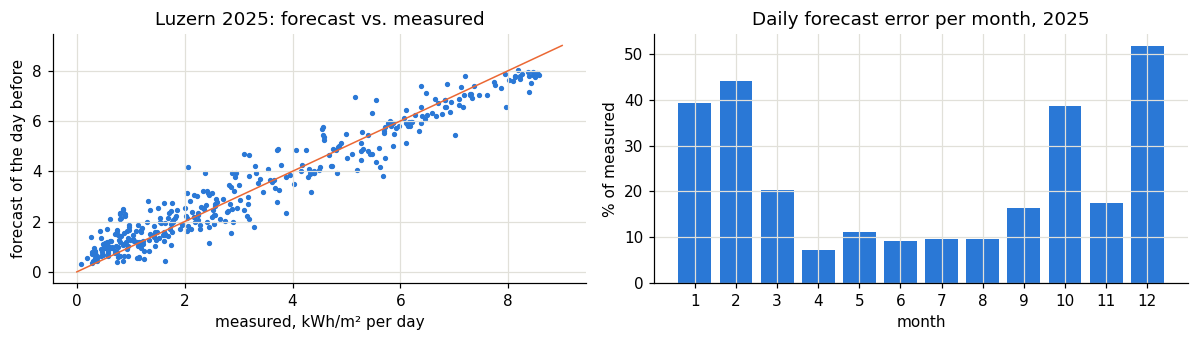

Winter days 2025 with fog pattern: 54 of 151
Mean forecast / measured, fog days: 2.04 | other winter days: 0.99


,"MAE, kWh/m2 per day","measured, kWh/m2 per day","MAE, % of measured"
1,0.4,1.1,39.4
2,0.6,1.3,44.1
3,0.6,2.9,20.3
4,0.4,5.0,7.3
5,0.5,4.7,11.2
6,0.6,6.7,9.2
7,0.5,5.2,9.6
8,0.5,5.3,9.7
9,0.5,3.3,16.5
10,0.7,1.8,38.7


In [11]:
p = pd.concat([luz["shortwave_radiation_icon_d2"], measured["radiation_LUZ"], measured["radiation_PIL"]], axis=1,
              keys=["forecast", "measured", "pilatus"]).dropna().loc["2025"]
d = p.resample("D").mean() * 24 / 1000
month = pd.DataFrame({"MAE, kWh/m2 per day": (d["forecast"] - d["measured"]).abs().groupby(d.index.month).mean(),
                      "measured, kWh/m2 per day": d["measured"].groupby(d.index.month).mean()})
month["MAE, % of measured"] = month.iloc[:, 0] / month.iloc[:, 1] * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].scatter(d["measured"], d["forecast"], s=6, color=BLUE)
axes[0].plot([0, 9], [0, 9], color=ORANGE, linewidth=1)
axes[0].set_xlabel("measured, kWh/m² per day")
axes[0].set_ylabel("forecast of the day before")
axes[0].set_title("Luzern 2025: forecast vs. measured")
axes[1].bar(month.index, month["MAE, % of measured"], color=BLUE)
axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel("month")
axes[1].set_ylabel("% of measured")
axes[1].set_title("Daily forecast error per month, 2025")
plt.tight_layout()
save(fig, "forecast_vs_measured")
plt.show()

# Fog days: Pilatus more than twice as bright as Luzern
winter = d[d.index.month.isin([10, 11, 12, 1, 2])]
fog = winter["pilatus"] > 2 * winter["measured"]
print(f"Winter days 2025 with fog pattern: {fog.sum()} of {len(fog)}")
print("Mean forecast / measured, fog days:", round(winter.loc[fog, "forecast"].mean() / winter.loc[fog, "measured"].mean(), 2),
      "| other winter days:", round(winter.loc[~fog, "forecast"].mean() / winter.loc[~fog, "measured"].mean(), 2))
month.round(1)

> **Finding:** from April to August the daily error is about 10 %, but in **December, January, February and October it is 40–50 %**. On days with a fog pattern (Pilatus more than twice as bright as Luzern; 54 of 151 winter days in 2025) the model **predicts about twice the measured radiation**, on the other winter days it is right on average (0.99).
> **Consequence:** the weather forecast **does not see the fog**. This is the main weakness of G3, in the season that matters for security of supply. In percent the errors are large because the winter values are small, in kWh they are similar. We report errors per season.

## Q10: Why is this dataset suitable for our goals?

In [12]:
coverage = luz.loc["2025", "shortwave_radiation_icon_d2"].notna().mean() * 100
print(f"Coverage of the test year 2025, ICON-D2: {coverage:.2f} %")
print("Hours available before the test year (2024):", luz.loc["2024", "shortwave_radiation_icon_d2"].notna().sum())

Coverage of the test year 2025, ICON-D2: 100.00 %
Hours available before the test year (2024): 8337


> **Finding:** 100 % of the test year is available, and the forecast is close to the measurement outside the fog season. 2024 adds 8,337 hours for fitting a simple factor.
> **Consequence:** suitable for G3 as an input. It is not suitable as a long training series: for 2019–2023 no forecasts exist. Possible solution: learn the relationship between radiation and generation with *measured* radiation 2019–2024, and apply it to the *forecast* in 2025.
> **To question:** that assumes that forecast and measurement behave the same, which Q9 contradicts for fog days.

## Q11: Leakage. What exactly is known when?

For a forecast of tomorrow's hours, only information from today is allowed.

| Column | Known the day before? |
|---|---|
| `*_previous_day1` | **yes, this is its purpose**: the model run of about one day earlier |
| Open-Meteo *current* forecast or archive API | **no**: it would contain newer model runs or observations |
| Measured radiation of the target hour | **no**: leakage |

> **Finding:** we use only the `previous_day1` columns. The name says the value comes from a run about 24 hours earlier, so each hour of tomorrow comes from a run of a slightly different time, the last one late in the evening of the previous day.
> **Consequence:** the forecast is legal for "forecast made late in the evening for tomorrow". A forecast for a day-ahead market at noon would have older runs, and be slightly worse.
> **To question:** we took the meaning of `previous_day1` from its name. The documentation of Open-Meteo has to confirm it before we write it in the report.

## Q12: Baseline. Is the forecast better than the simple predictions?

In [13]:
m = measured["radiation_LUZ"]
test = m.loc["2025"]
train = m.loc["2019":"2024"]
profile = train.groupby([train.index.month, train.index.hour]).mean()
typical = pd.Series(profile.reindex(pd.MultiIndex.from_arrays([test.index.month, test.index.hour])).values, index=test.index)
forecast = luz["shortwave_radiation_icon_d2"].reindex(test.index)
baseline = pd.Series({
    "constant: mean of 2019-2024": (test - train.mean()).abs().mean() / test.mean() * 100,
    "typical hour of the month (2019-2024)": (typical - test).abs().mean() / test.mean() * 100,
    "same hour of the previous day": (m.shift(24).loc["2025"] - test).abs().mean() / test.mean() * 100,
    "weather forecast ICON-D2": (forecast - test).abs().mean() / test.mean() * 100,
}).round(1)
baseline.rename("MAE in % of the mean, radiation Luzern 2025").to_frame()

,"MAE in % of the mean, radiation Luzern 2025"
constant: mean of 2019-2024,125.4
typical hour of the month (2019-2024),45.6
same hour of the previous day,41.1
weather forecast ICON-D2,24.8


> **Finding:** on the hourly radiation in Luzern in 2025 the weather forecast is off by about **25 %** of the mean, the "same hour as yesterday" by 41 %, the typical hour of the month by 46 % and a constant by 125 %.
> **Consequence:** the forecast clearly beats all simple predictions, so it adds real information.

## Save the cleaned table for later use in the combined notebook

In [14]:
keep = ["shortwave_radiation_icon_d2", "temperature_2m_icon_d2", "cloud_cover_icon_d2"]
wide = df.pivot(columns="location", values=keep)
wide.columns = [f"forecast_{value.split('_')[0]}_{location}" for value, location in wide.columns]
wide.index.name = "time_local"
OUT.mkdir(parents=True, exist_ok=True)
wide.to_csv(OUT / "open_meteo_forecast.csv")
print(wide.shape, list(wide.columns)[:4], "...")

(17543, 12) ['forecast_shortwave_EGO', 'forecast_shortwave_LUZ', 'forecast_shortwave_MOA', 'forecast_shortwave_SPF'] ...


# Summary

## Decision log

| # | Issue | Error or characteristic? | Decision | Affected |
|---|---|---|---|---|
| Q3 | ICON-D2 starts on 19.1.2024, ICON-CH2 on 4.7.2025 | characteristic (missing by design) | use ICON-D2; not filled | 447 hours in 2024 |
| Q4 | Radiation is the mean of the preceding hour, delivered in UTC | characteristic | fixed CET, radiation shifted by −1 h; temperature and cloud cover not shifted | all rows |
| Q6 | Cloud cover stays at 100 % for days | characteristic | kept | few hours |
| Q7 | Shortwave = direct + diffuse | redundant | only `shortwave_radiation` | – |
| Q9 | Forecast about 2 times too high on fog days | characteristic of the model | kept; errors reported per season | about a third of the winter days 2025 |
| Q11 | Only `previous_day1` is known in advance | leakage risk | no other forecast or archive columns | – |

## Is the data suitable? (Insights)

**Yes as the input for G3, only partly for winter.** The test year is complete, and the forecast is clearly better than all simple predictions. Limits: there is only one earlier year (2024), and the model does not see fog, so the winter errors will stay high.

## Open questions (to discuss)

1. Does the Open-Meteo documentation confirm what exactly `previous_day1` means (run time, lead time)?
2. Should Pilatus-based fog information of the previous day be added as an input? It would be known in advance.
3. Learn the relationship with measured radiation 2019–2024, or only with forecasts in 2024?

## Next steps (Step 3 of the guide)

- Cleaned table: `data/processed/open_meteo_forecast.csv`.
- Combined notebook: add the forecasts and the simple baseline of G3 (radiation forecast × monthly factor).